# Desk location strategy — validation

Rules under test, matching the watchlist and the 5-minute chart:

| Layer | Rule | Fill |
|---|---|---|
| On list | Day change ≥ +4% and volume ≥ 2× the prior 50 sessions | Next session open |
| Hot | Day change ≥ +10% and volume ≥ 5× | Next session open |
| Ribbon | Close above a rising EMA200, at least 20 sessions above it, within 1.5 ATR of the ribbon | Next session open |
| Strict daily book | On list **and** ribbon. Hold 5 sessions, or exit the close that loses EMA200 | Next open, close exit |
| 5-minute long | Close above the higher of session VWAP and week AVWAP, then a later retest holds | Next 5-minute open |
| 5-minute short | Close below the lower of the two lines, then a later retest fails | Next 5-minute open |

Session VWAP resets each US/Eastern date. Week AVWAP resets each Monday. Both use typical price × volume, the same loop as `src/lib/vwap.ts`.

Costs are 2 bps per side on the books. The event table is gross of costs. In-sample is 2023-01-01 through 2024-12-31. Out-of-sample starts 2025-01-01. The 5-minute book uses Yahoo's recent 5-minute window only (about 60 sessions); that is the history the feed keeps.

Three 5-minute variants:

- **strict** — long only after an on-list day that also held the ribbon; short only after a close under EMA200
- **ribbon** — long after a ribbon hold, short after a close under EMA200, no +4% day required
- **location** — VWAP / AVWAP retest alone

Universe: SPY, QQQ, and 18 liquid names including AIZ. Each symbol-day is one event. This is a research harness, not an order blotter.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT.name and not (ROOT / "pipeline").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pipeline.research.desk_location import (
    make_figures,
    narrate,
    run_study,
    save_tables,
)

OUT = ROOT / "pipeline" / "research" / "artifacts" / "desk_location"
result = run_study()
save_tables(result, OUT)
figures = make_figures(result, OUT)
print(f"Daily symbols: {len(result.meta['daily_symbols'])}")
print(f"5-minute symbols: {len(result.meta['intraday_symbols'])}")
print("Figures:", ", ".join(p.name for p in figures))


Daily symbols: 20
5-minute symbols: 20
Figures: forward_5d.png, forward_5d_is_oos.png, daily_equity.png, daily_trade_distribution.png, intraday_equity.png, aiz_vwap.png


## Daily qualification

Forward return is from the next session's open to the close `h` sessions after the signal. `all_sessions` is the base rate. `up_not_listed` is a green day that missed the +4% / 2× gate.


In [2]:
show = result.events[result.events["horizon_sessions"].isin([1, 5, 20])].copy()
show.sort_values(["horizon_sessions", "sample", "group"])


,group,horizon_sessions,sample,n,mean_pct,median_pct,win_rate_pct,se_pct
60,all_sessions,1,all,19280,0.048,0.061,52.11,0.011
12,hot,1,all,4,2.105,1.397,75.00,2.102
0,on_list,1,all,146,-0.350,-0.348,41.10,0.210
36,on_list_and_ribbon,1,all,1,-1.843,-1.843,0.00,NaN
24,ribbon,1,all,998,0.037,0.097,52.30,0.051
48,up_not_listed,1,all,10198,0.045,0.077,52.64,0.015
61,all_sessions,1,is,10020,0.071,0.085,53.05,0.014
13,hot,1,is,4,2.105,1.397,75.00,2.102
1,on_list,1,is,75,0.344,0.065,50.67,0.318
37,on_list_and_ribbon,1,is,0,NaN,NaN,NaN,NaN


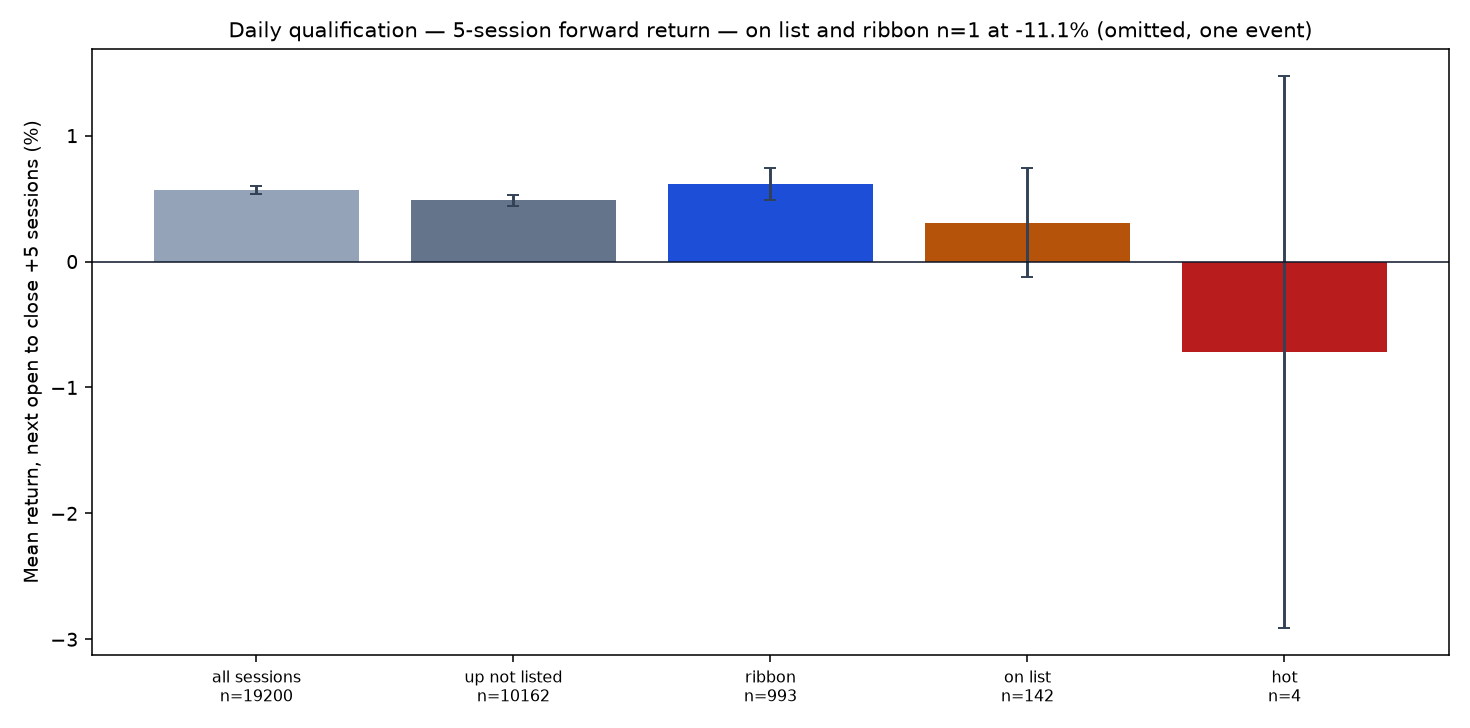

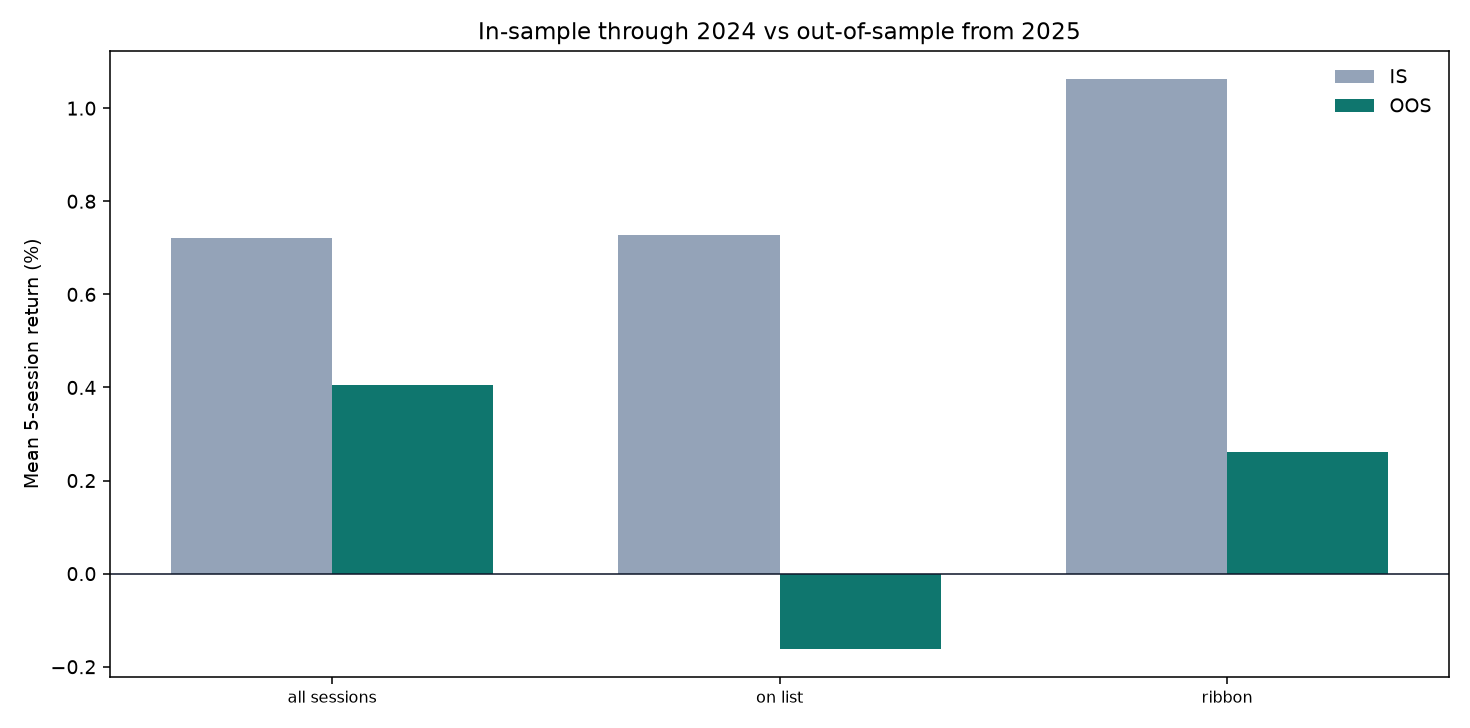

In [3]:
from IPython.display import Image, display

display(Image(filename=str(OUT / "forward_5d.png")))
display(Image(filename=str(OUT / "forward_5d_is_oos.png")))


## Daily books

Equal weight across names that are in a trade that session. Cash earns zero. SPY is buy-and-hold over the same dates. The dashed line is the out-of-sample start.


In [4]:
result.daily_metrics


,book,sample,sessions,trades,win_rate_pct,avg_trade_pct,median_trade_pct,profit_factor,sharpe,total_return_pct,max_drawdown_pct
0,on_list,all,965,131,55.73,0.445,0.435,1.27,0.608,55.55,-34.37
1,on_list,is,502,67,62.69,1.082,0.894,1.80,1.132,56.57,-25.81
2,on_list,oos,463,64,48.44,-0.223,-0.189,0.89,0.108,-0.65,-34.37
3,ribbon,all,965,291,50.52,0.457,0.035,1.34,0.377,24.24,-31.55
4,ribbon,is,502,128,54.69,1.061,0.688,1.94,1.153,48.69,-16.41
5,ribbon,oos,463,163,47.24,-0.017,-0.368,0.99,-0.305,-16.45,-31.55
6,on_list_and_ribbon,all,965,1,0.00,-11.152,-11.152,0.00,-1.028,-11.15,-11.15
7,on_list_and_ribbon,is,502,0,0.00,0.000,0.000,NaN,0.000,0.00,0.00
8,on_list_and_ribbon,oos,463,1,0.00,-11.152,-11.152,0.00,-1.487,-11.15,-11.15
9,spy,all,965,0,0.00,0.000,0.000,NaN,1.300,101.95,-18.76


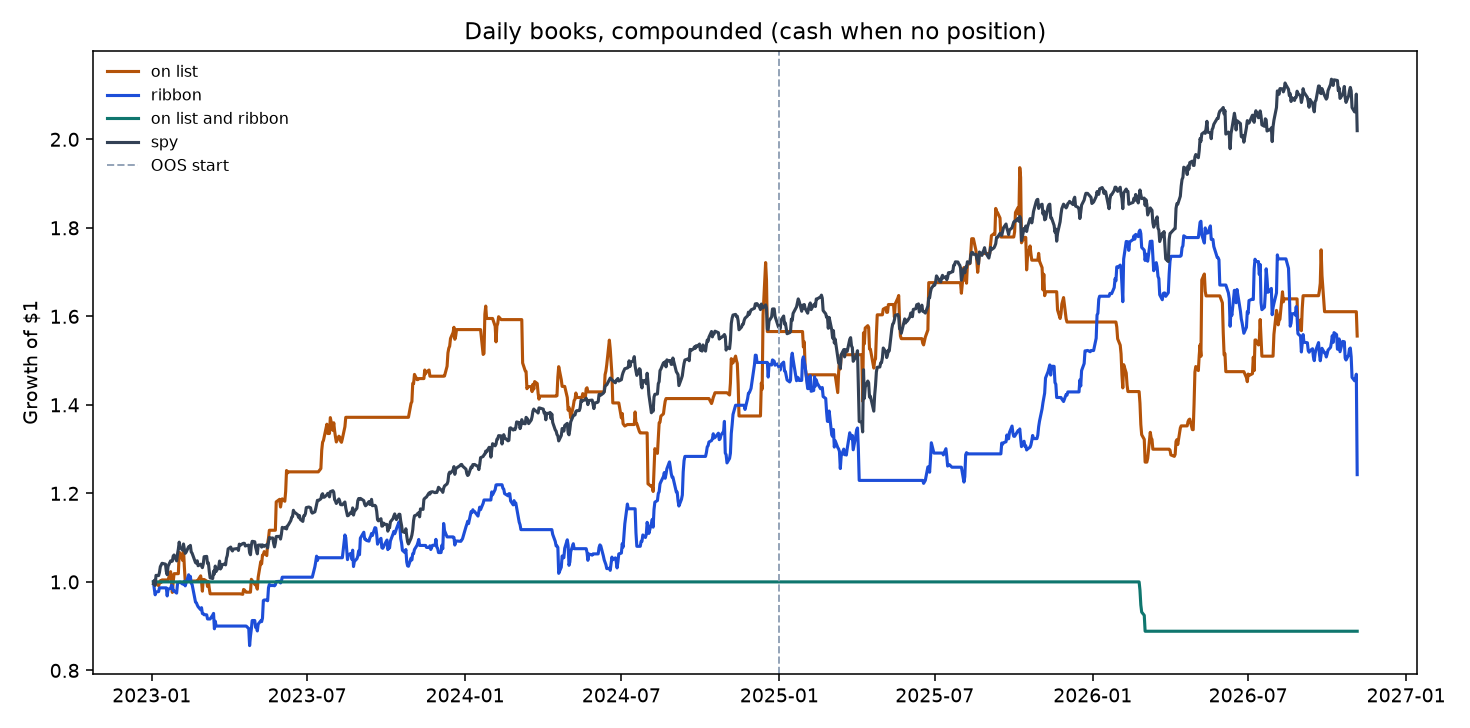

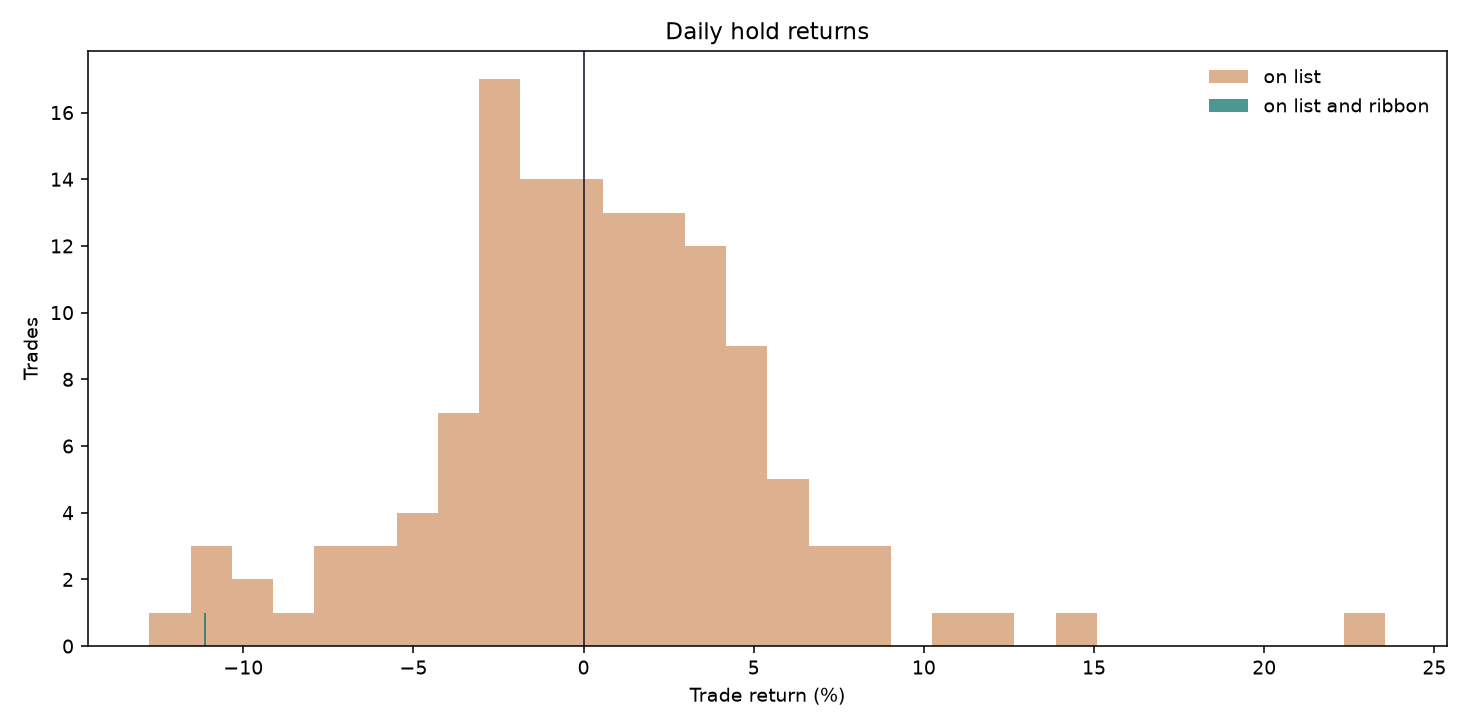

In [5]:
display(Image(filename=str(OUT / "daily_equity.png")))
display(Image(filename=str(OUT / "daily_trade_distribution.png")))


## Five-minute VWAP / AVWAP

A long arms when a bar closes above the higher of the session VWAP and the week AVWAP. Entry is the next bar's open after a later bar trades back to that line and closes back above it (12-bar window). Exit is the next open after a close through the entry line or through the session VWAP. Shorts mirror this around the lower line and the week AVWAP. Open trades flatten at the end of the downloaded tape. The equity curve compounds the equal-weight mean of the trades that closed on each session, so a day with many exits counts once.


In [6]:
result.intraday_stats


,variant,side,trades,win_rate_pct,avg_trade_pct,median_trade_pct,profit_factor,session_book_pct
0,strict,all,266,16.17,0.075,-0.145,1.35,2.17
1,strict,long,0,0.00,0.000,0.000,NaN,NaN
2,strict,short,266,16.17,0.075,-0.145,1.35,NaN
3,ribbon,all,404,17.08,0.012,-0.145,1.05,1.84
4,ribbon,long,138,18.84,-0.110,-0.142,0.50,NaN
5,ribbon,short,266,16.17,0.075,-0.145,1.35,NaN
6,location,all,2321,14.48,-0.078,-0.138,0.66,-4.05
7,location,long,1219,15.75,-0.095,-0.131,0.57,NaN
8,location,short,1102,13.07,-0.060,-0.144,0.75,NaN


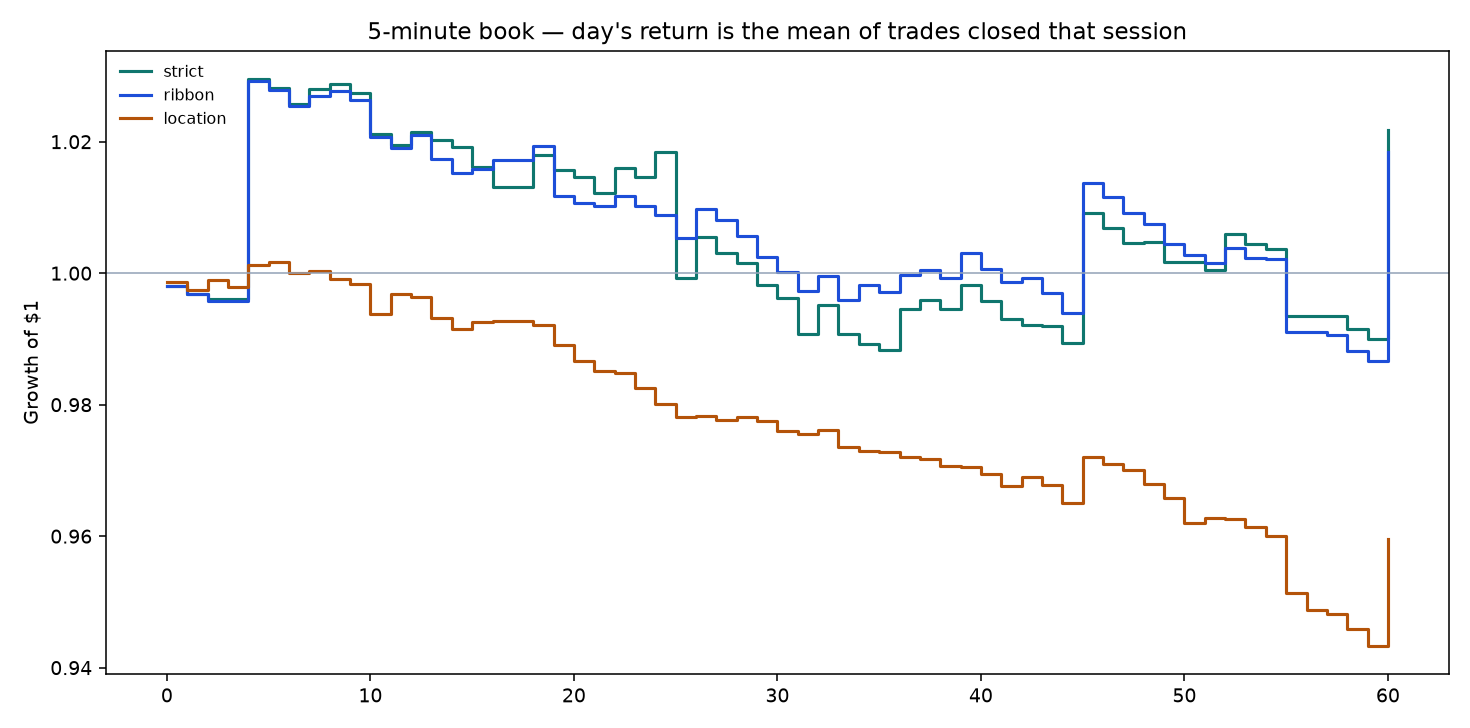

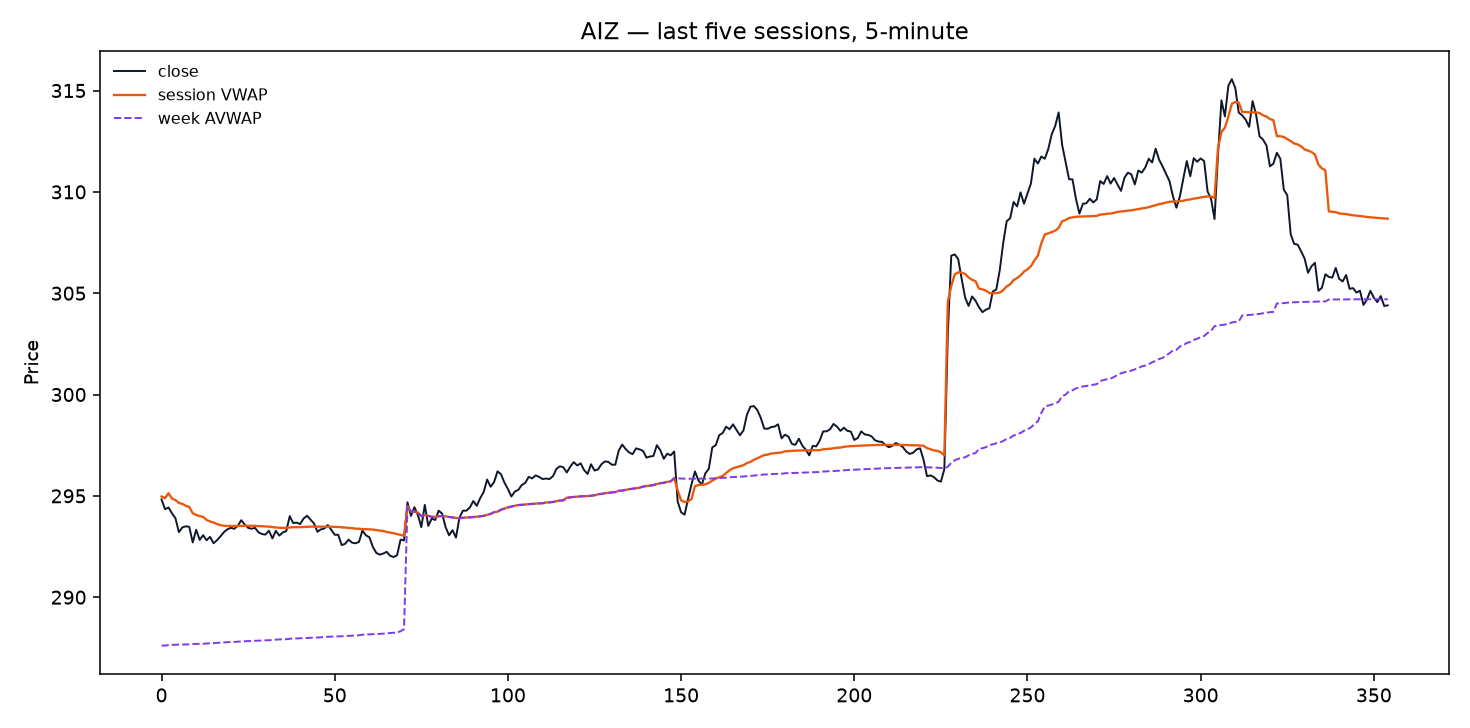

In [7]:
display(Image(filename=str(OUT / "intraday_equity.png")))
aiz = OUT / "aiz_vwap.png"
if aiz.exists():
    display(Image(filename=str(aiz)))
else:
    print("AIZ 5-minute tape was not in this download.")


## Reading


In [8]:
print(narrate(result))


Five-session forward returns from the next open (all symbols pooled, 2 bps per side is not in this event table):
- on_list: n=142, mean +0.309%, median +0.448%, win rate 54.9%
- hot: n=4, mean -0.719%, median -1.701%, win rate 25.0%
- ribbon: n=993, mean +0.614%, median +0.472%, win rate 55.5%
- on_list_and_ribbon: n=1, mean -11.112%, median -11.112%, win rate 0.0%
- up_not_listed: n=10162, mean +0.487%, median +0.484%, win rate 56.5%
- all_sessions: n=19200, mean +0.570%, median +0.518%, win rate 56.6%
Daily books versus SPY (compounded session returns, 2 bps per side):
- on_list all: trades 131, avg trade +0.445%, Sharpe 0.608, total +55.55%, max DD -34.37%
- on_list is: trades 67, avg trade +1.082%, Sharpe 1.132, total +56.57%, max DD -25.81%
- on_list oos: trades 64, avg trade -0.223%, Sharpe 0.108, total -0.65%, max DD -34.37%
- ribbon all: trades 291, avg trade +0.457%, Sharpe 0.377, total +24.24%, max DD -31.55%
- ribbon is: trades 128, avg trade +1.061%, Sharpe 1.153, total +48